In [1]:
# Imports
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Suppress harmless statsmodels convergence warnings
warnings.filterwarnings("ignore")

### Vorverarbeitung der Daten

In [2]:
df = pd.read_csv("data.csv")
df["date"] = pd.to_datetime(df["DateTime"])

# Tarife werden vorerst zusammengelegt, "date" wird dabei als Index übernommen
df = df.groupby("date").agg({"KWH": "sum", "meters": "sum"})

# Normalisierung: Stromverbrauch eines Verbrauchers für jeden Zeitpunkt
df["kwh"] = df["KWH"] / df["meters"]

df = df[["KWH", "kwh", "meters"]]
display(df)

,KWH,kwh,meters
date,,,
2011-11-23 09:00:00,0.569000,0.284500,2
2011-11-23 09:30:00,0.561000,0.280500,2
2011-11-23 10:00:00,0.920000,0.153333,6
2011-11-23 10:30:00,0.588000,0.098000,6
2011-11-23 11:00:00,0.772000,0.110286,7
...,...,...,...
2014-02-27 22:00:00,1494.603000,0.299760,4986
2014-02-27 22:30:00,1422.109001,0.285163,4987
2014-02-27 23:00:00,1258.090000,0.252274,4987


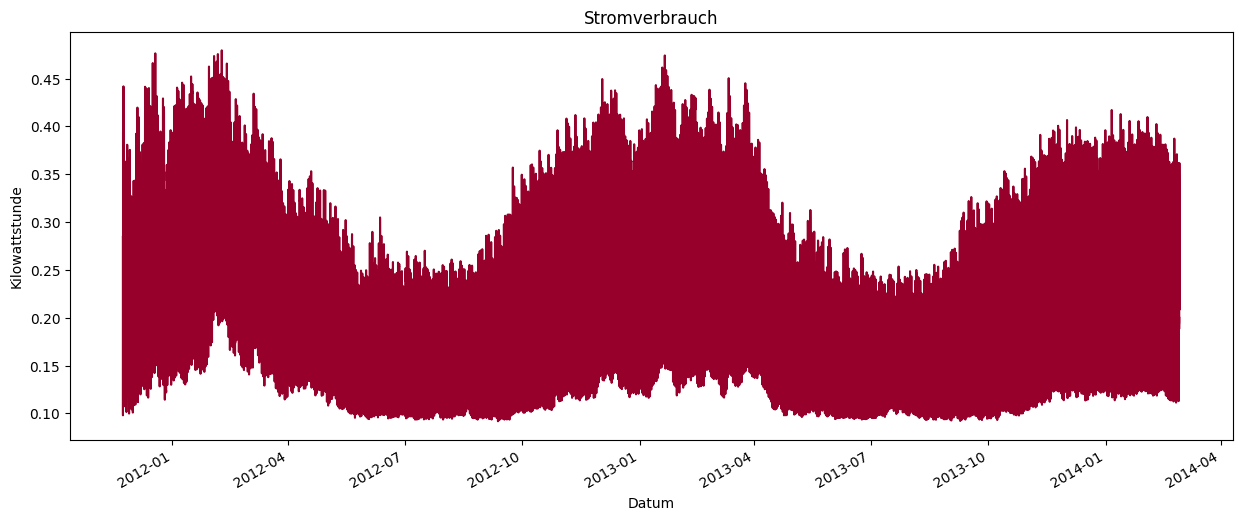

In [3]:
# Erste Visualisierung des Datensatzes
series = df["kwh"].sort_index()

fig, ax = plt.subplots(figsize=(15, 6))
series.plot(ax=ax, color="#96002A")
ax.set(
    title="Stromverbrauch",
    xlabel="Datum",
    ylabel="Kilowattstunde",
)
plt.show()

### Datenbereinigung

Im Datensatz sind fehlerhaft Datenpunkte enthalten, bei denen kein Verbraucher geschaltet ist und die Messungen außerhalb dem 30-Minuten-Taktes liegen.

In [4]:
# Prüfung auf Datenpunkte mit keinem Verbrauch
display(df.loc[(df["KWH"] == 0)])

# Falls die Prüfungen nichts zurückliefern, können die fehlerhaften Datenpunkte entfernt werden
# Prüfung auf korrekte Datenpunkte mit keinem Verbrauch
display(df.loc[(df["KWH"] == 0) & ((df.index.minute % 30 == 0) & (df.index.second == 0))])
# Prüfung auf korrekte Datenpunkte außerhalb des 30-Minuten-Taktes
display(df.loc[~(df["KWH"] == 0) & ~((df.index.minute % 30 == 0) & (df.index.second == 0))])

# Durch .asfreq() fallen die fehlerhaften Datenpunkte weg
df = df.sort_index().asfreq("30min")
display(df["kwh"].isna().sum())

,KWH,kwh,meters
date,,,
2012-12-18 15:13:26,0.0,NaN,0
2012-12-18 15:13:27,0.0,NaN,0
2012-12-18 15:13:28,0.0,NaN,0
2012-12-18 15:13:29,0.0,NaN,0
2012-12-18 15:13:30,0.0,NaN,0
...,...,...,...
2013-07-05 12:54:31,0.0,NaN,0
2013-07-05 13:15:05,0.0,NaN,0
2013-09-20 18:24:09,0.0,NaN,0


,KWH,kwh,meters
date,,,


,KWH,kwh,meters
date,,,


np.int64(0)

### Untersuchung der Zeitreihe auf Trend, Saisonalität und Residuum

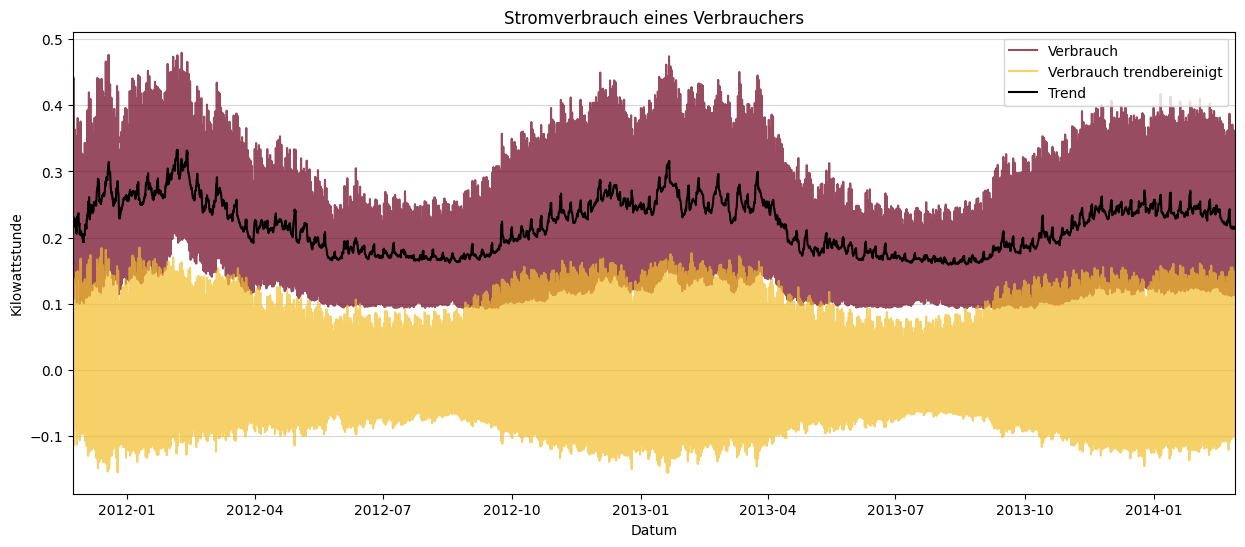

,KWH,kwh,meters,kwh_trend,kwh_trendbereinigt
date,,,,,
2011-11-23 09:00:00,0.569000,0.284500,2,NaN,NaN
2011-11-23 09:30:00,0.561000,0.280500,2,NaN,NaN
2011-11-23 10:00:00,0.920000,0.153333,6,NaN,NaN
2011-11-23 10:30:00,0.588000,0.098000,6,NaN,NaN
2011-11-23 11:00:00,0.772000,0.110286,7,NaN,NaN
...,...,...,...,...,...
2014-02-27 22:00:00,1494.603000,0.299760,4986,NaN,NaN
2014-02-27 22:30:00,1422.109001,0.285163,4987,NaN,NaN
2014-02-27 23:00:00,1258.090000,0.252274,4987,NaN,NaN


In [5]:
def analyse_trend(df: pd.DataFrame) -> pd.DataFrame:
    fig, ax = plt.subplots(figsize=(15, 6))
    ax.margins(x=0)

    df["kwh_trend"] = df["kwh"].rolling(window=48, center=True).mean()  # Mit Glättung über einen Tag

    df["kwh_trendbereinigt"] = df["kwh"] - df["kwh_trend"]
    ax.plot(df.index, df["kwh"], color="#6B001E", alpha=0.7, label="Verbrauch")
    ax.plot(df.index, df["kwh_trendbereinigt"], color="#F3BE2B", alpha=0.7, label="Verbrauch trendbereinigt")
    ax.plot(df.index, df["kwh_trend"], color="#000000", alpha=1, label="Trend")
    ax.set(
        title="Stromverbrauch eines Verbrauchers",
        xlabel="Datum",
        ylabel="Kilowattstunde",
    )
    ax.legend()
    ax.grid(axis="y", alpha=0.5)
    plt.show()

    return df


df = analyse_trend(df)
df

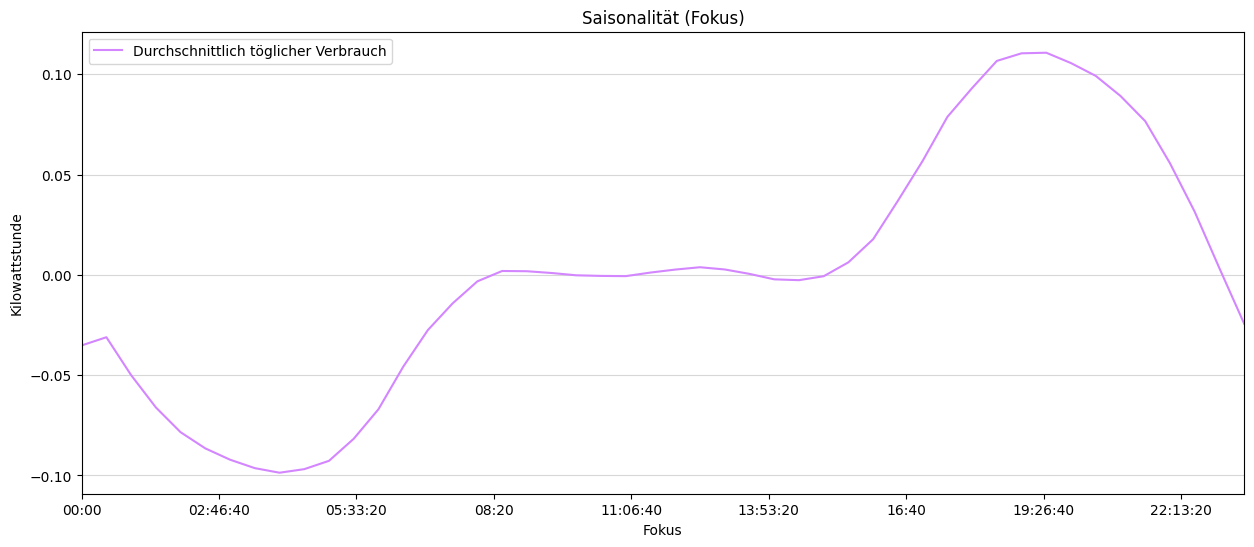

In [6]:
def analyse_seasonality(df: pd.DataFrame) -> pd.DataFrame:
    # Gruppierung nach Uhrzeit pro Tag
    df["focus"] = df.index.time

    seasonal = df.groupby("focus")["kwh_trendbereinigt"].mean()
    # .transform berechnet den Mittelwert pro Gruppe und weist ihn jedem Datenpunkt der Gruppe zu
    df["kwh_trendbereinigt_saison"] = df.groupby("focus")["kwh_trendbereinigt"].transform("mean")

    fig, ax = plt.subplots(figsize=(15, 6))
    ax.margins(x=0)

    seasonal.plot(ax=ax, color="#D386FF", alpha=1, label="Durchschnittlich töglicher Verbrauch")
    ax.set(
        title="Saisonalität (Fokus)",
        xlabel="Fokus",
        ylabel="Kilowattstunde",
    )
    ax.legend()
    ax.grid(axis="y", alpha=0.5)
    plt.show()
    

    df = df.drop(columns=["focus"])
    return df
    


df = analyse_seasonality(df)
# df

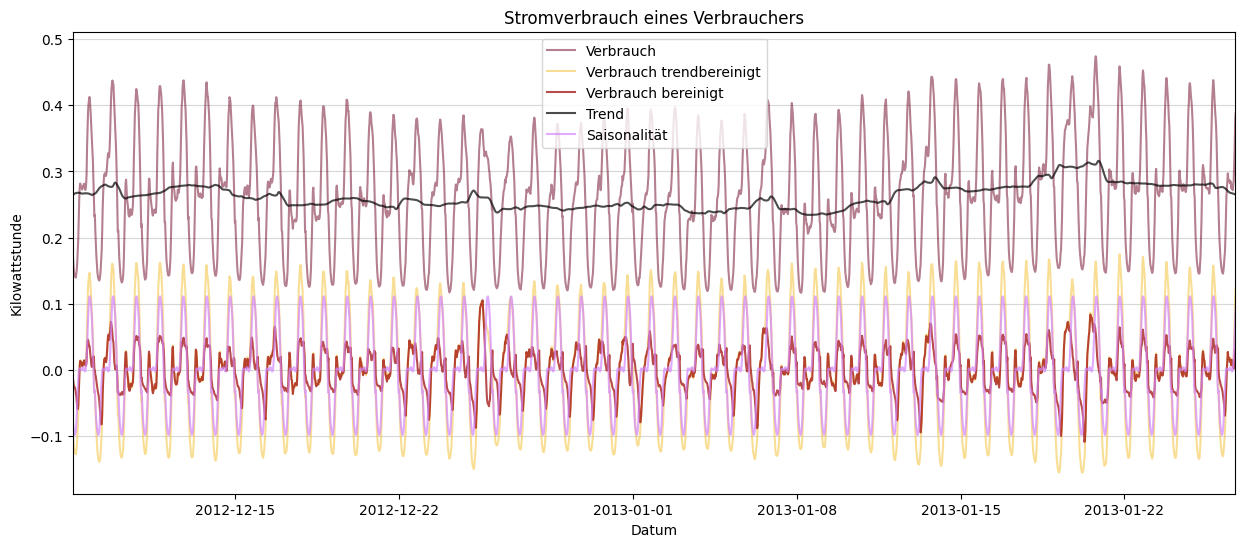

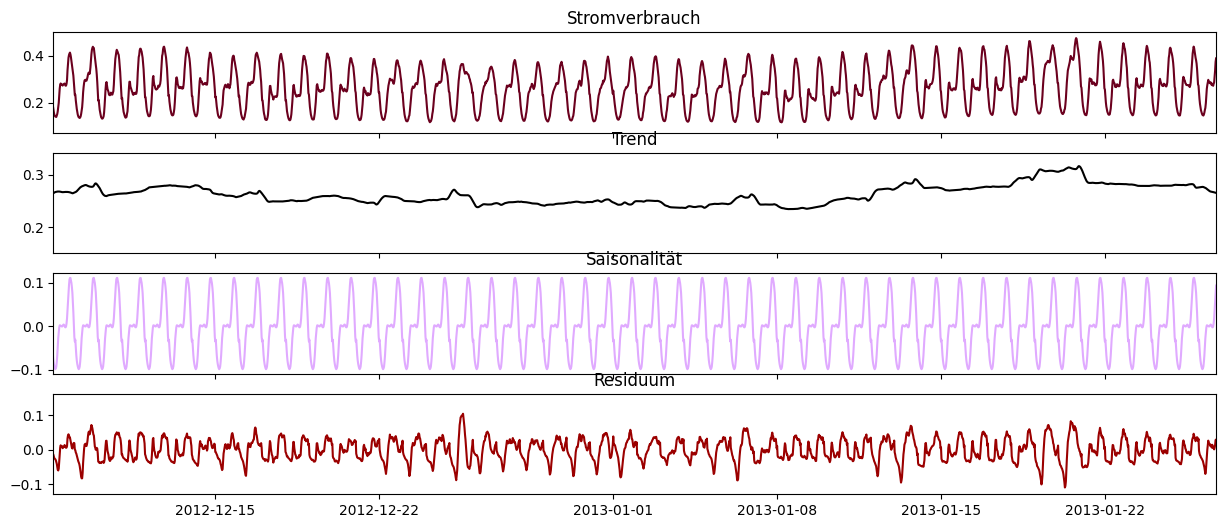

In [7]:
def analyse_cleaned(df: pd.DataFrame) -> pd.DataFrame:
    fig, ax = plt.subplots(figsize=(15, 6))
    ax.margins(x=0)
    # TODO: Hier sollte gleiches Ergebnis wie mit .shift(48) rauskommen???
    # Nein: "kwh_trendbereinigt_saison" verwendet den Durchschnitt über alle Tage pro Zeitpunkt,
    # während .shift(48) den exakten Wert des Vortages nimmt – beides entfernt Saisonalität, aber auf unterschiedliche Weise.

    # Berechnung des Residuums: kwh_bereinigt = kwh_trendbereinigt - kwh_trendbereinigt_saison
    #                                         = (kwh - Trend)      - Saisonalität
    df["kwh_bereinigt"] = df["kwh_trendbereinigt"] - df["kwh_trendbereinigt_saison"]

    ax.plot(df.index, df["kwh"], color="#6B001E", alpha=0.5, label="Verbrauch")
    ax.plot(df.index, df["kwh_trendbereinigt"], color="#F3BE2B", alpha=0.5, label="Verbrauch trendbereinigt")
    ax.plot(df.index, df["kwh_bereinigt"], color="#9B0000", alpha=0.7, label="Verbrauch bereinigt")
    ax.plot(df.index, df["kwh_trend"], color="#000000FF", alpha=0.7, label="Trend")
    ax.plot(df.index, df["kwh_trendbereinigt_saison"], color="#D386FF", alpha=0.7, label="Saisonalität")
    ax.set(
        title="Stromverbrauch eines Verbrauchers",
        xlabel="Datum",
        ylabel="Kilowattstunde",
    )
    ax.set_xlim(pd.Series(df.index).quantile(0.46), pd.Series(df.index).quantile(0.52))  # Begrenzung auf Zeitraum
    ax.legend()
    ax.grid(axis="y", alpha=0.5)
    plt.show()

    # Getrennte Plots
    fig, ax = plt.subplots(4, 1, figsize=(15, 6), sharex=True)

    for p in ax:
        p.set_xlim(pd.Series(df.index).quantile(0.46), pd.Series(df.index).quantile(0.52))

    ax[0].plot(df["kwh"], color="#6B001E")
    ax[0].set_title("Stromverbrauch")

    ax[1].plot(df["kwh_trend"], color="#000000FF")
    ax[1].set_title("Trend")

    ax[2].plot(df["kwh_trendbereinigt_saison"], color="#D386FF", alpha=0.7)
    ax[2].set_title("Saisonalität")

    ax[3].plot(df["kwh_bereinigt"], color="#9B0000")
    ax[3].set_title("Residuum")

    plt.show()
    return df


df = analyse_cleaned(df)

### Verwendung von STL
Die manuelle Zerlegung basiert auf einem einfachen additiven Modell, das den Trend per gleitendem Durchschnitt und die Saisonalität als festen Tagesdurchschnitt schätzt. Beide Komponenten werden sequenziell und ohne Rückkopplung berechnet, was zu Ungenauigkeiten führt: Ausreißer verzerren den Trend, und eine einmalige Mittelung erfasst keine Schwankungen in der Saisonalität über die Zeit.

STL (*Seasonal and Trend decomposition using Loess*) behebt dies durch einen iterativen Prozess, der Trend und Saisonalität wechselseitig verfeinert. Die Loess-Glättung ist dabei robuster gegenüber Ausreißern, und die Saisonalitätskomponente kann sich über den Beobachtungszeitraum hinweg verändern. Das Residuum ist dadurch sauberer isoliert und repräsentiert tatsächlich nur den zufälligen Rest.

Die zugrundeliegende Loess-Glättung (*Locally Estimated Scatterplot Smoothing*) schätzt den Wert an jedem Punkt anhand einer gewichteten Regression über seine unmittelbare Nachbarschaft – nahe Punkte erhalten dabei mehr Gewicht als entfernte. Dadurch passt sich die Glättung lokalen Mustern an, statt eine globale Kurve zu erzwingen, und ist zudem robuster gegenüber Ausreißern, da diese in der Regression weniger stark ins Gewicht fallen.

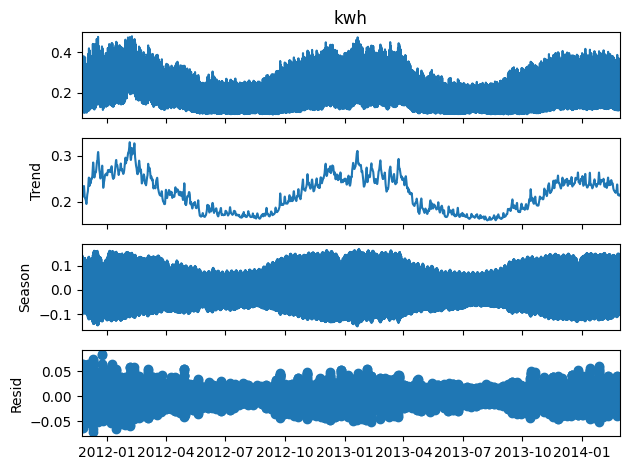

In [8]:
from statsmodels.tsa.seasonal import STL

decomposition = STL(
    df["kwh"],
    period=48,
)
decomposition = decomposition.fit()
_ = decomposition.plot()

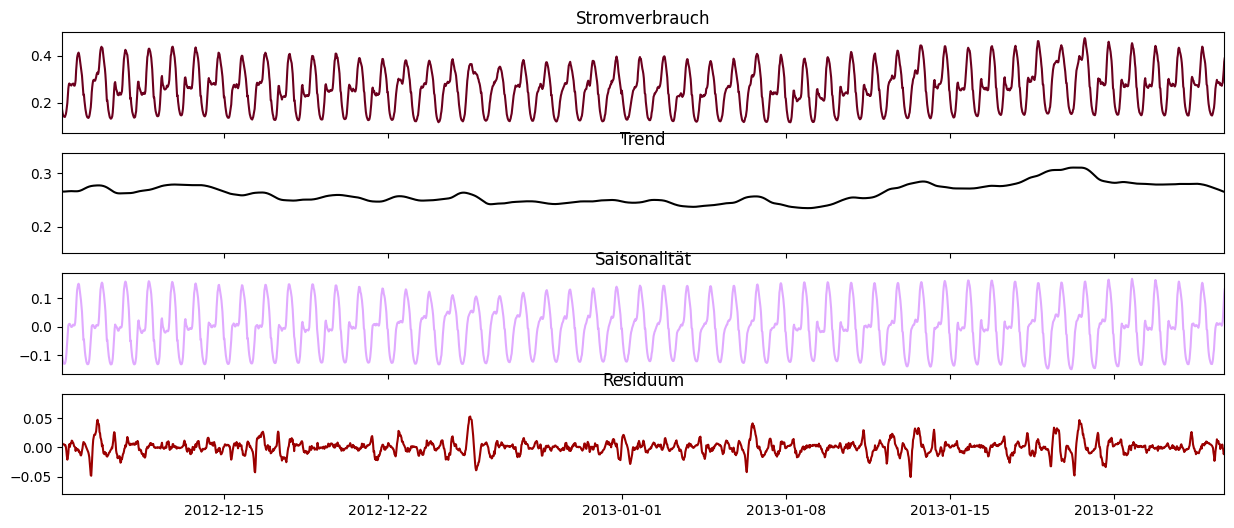

In [9]:
fig, ax = plt.subplots(4, 1, figsize=(15, 6), sharex=True)

for p in ax:
    p.set_xlim(pd.Series(df.index).quantile(0.46), pd.Series(df.index).quantile(0.52))

ax[0].plot(df["kwh"], color="#6B001E")
ax[0].set_title("Stromverbrauch")

ax[1].plot(decomposition.trend, color="#000000FF")
ax[1].set_title("Trend")

ax[2].plot(decomposition.seasonal, color="#D386FF", alpha=0.7)
ax[2].set_title("Saisonalität")

ax[3].plot(decomposition.resid, color="#9B0000")
ax[3].set_title("Residuum")

plt.show()

### Weiterverwendung von STL Werten

In [10]:
df["kwh_trend"] = decomposition.trend
df["kwh_trendbereinigt"] = df["kwh"] - df["kwh_trend"]
df["kwh_trendbereinigt_saison"] = decomposition.seasonal
df["kwh_bereinigt"] = decomposition.resid

df

,KWH,kwh,meters,kwh_trend,kwh_trendbereinigt,kwh_trendbereinigt_saison,kwh_bereinigt
date,,,,,,,
2011-11-23 09:00:00,0.569000,0.284500,2,0.228392,0.056108,0.015254,0.040854
2011-11-23 09:30:00,0.561000,0.280500,2,0.228330,0.052170,0.007901,0.044269
2011-11-23 10:00:00,0.920000,0.153333,6,0.228268,-0.074934,-0.046019,-0.028915
2011-11-23 10:30:00,0.588000,0.098000,6,0.228205,-0.130205,-0.094325,-0.035879
2011-11-23 11:00:00,0.772000,0.110286,7,0.228142,-0.117856,-0.094211,-0.023646
...,...,...,...,...,...,...,...
2014-02-27 22:00:00,1494.603000,0.299760,4986,0.215672,0.084088,0.085840,-0.001751
2014-02-27 22:30:00,1422.109001,0.285163,4987,0.215690,0.069473,0.069239,0.000235
2014-02-27 23:00:00,1258.090000,0.252274,4987,0.215708,0.036566,0.038879,-0.002313


### Autokorrelation und Partielle Autokorrelation

Die **PACF** zeigt einen einzigen signifikanten Lag bei t-1, was auf einen **AR(1)-Prozess** hindeutet:
der aktuelle Wert hängt direkt fast ausschließlich vom unmittelbar vorangegangenen Zeitpunkt ab.

Die **ACF** bestätigt dieses Bild durch ein langsames Abklingen der positiven Korrelation in den ersten Lags.
Der Wechsel in negative Werte ab Lag ~9 (entspricht ca. 4,5 Stunden) deutet auf einen schwachen
**zyklischen Tagesrhythmus** im Residuum hin, der durch die STL-Zerlegung nicht vollständig erfasst wurde.

In [11]:
df["kwh_bereinigt"]

date
2011-11-23 09:00:00    0.040854
2011-11-23 09:30:00    0.044269
2011-11-23 10:00:00   -0.028915
2011-11-23 10:30:00   -0.035879
2011-11-23 11:00:00   -0.023646
                         ...   
2014-02-27 22:00:00   -0.001751
2014-02-27 22:30:00    0.000235
2014-02-27 23:00:00   -0.002313
2014-02-27 23:30:00    0.000213
2014-02-28 00:00:00   -0.000036
Freq: 30min, Name: kwh_bereinigt, Length: 39727, dtype: float64

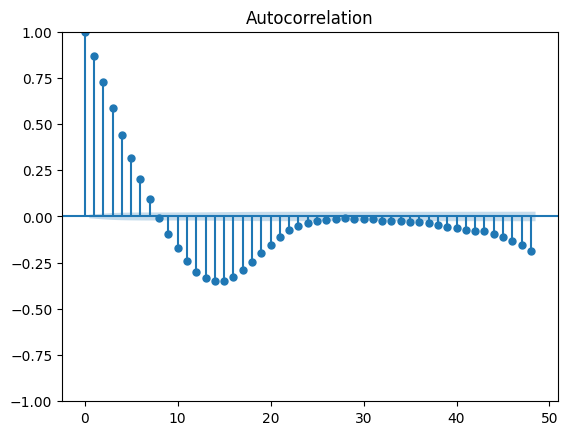

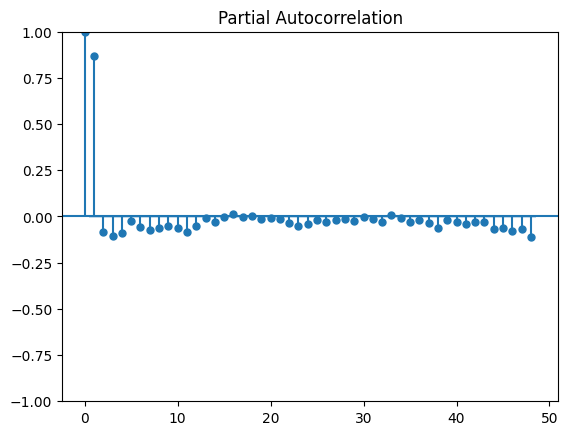

In [12]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

_ = plot_acf(df["kwh_bereinigt"], lags=48)
_ = plot_pacf(df["kwh_bereinigt"], lags=48)
plt.show()

### Vorhersage mit Linearer Regression
Zielvariable hier ist der tatsächliche Verbrauch 6 Stunden in der Zukunft

In [13]:
df_model = df.copy()
lags = []
for lag in range(1, 13):
    col_name = f"kwh_bereinigt_t-{lag}"
    df_model[col_name] = df_model["kwh_bereinigt"].shift(lag)
    lags.append(col_name)
df_model["kwh_target"] = df_model["kwh"].shift(-12) # Zielwert: Vorherzusagener Wert 6 Stunden in der Zukunft 
df_model = df_model.dropna()
df_model

,KWH,kwh,meters,kwh_trend,kwh_trendbereinigt,kwh_trendbereinigt_saison,kwh_bereinigt,kwh_bereinigt_t-1,kwh_bereinigt_t-2,kwh_bereinigt_t-3,kwh_bereinigt_t-4,kwh_bereinigt_t-5,kwh_bereinigt_t-6,kwh_bereinigt_t-7,kwh_bereinigt_t-8,kwh_bereinigt_t-9,kwh_bereinigt_t-10,kwh_bereinigt_t-11,kwh_bereinigt_t-12,kwh_target
date,,,,,,,,,,,,,,,,,,,,
2011-11-23 15:00:00,2.770000,0.213077,13,0.227636,-0.014559,-0.024323,0.009763,0.014152,0.022825,0.022976,0.013922,0.058331,0.063241,-0.000788,-0.023646,-0.035879,-0.028915,0.044269,0.040854,0.346692
2011-11-23 15:30:00,2.132000,0.164000,13,0.227573,-0.063573,-0.059733,-0.003839,0.009763,0.014152,0.022825,0.022976,0.013922,0.058331,0.063241,-0.000788,-0.023646,-0.035879,-0.028915,0.044269,0.318538
2011-11-23 16:00:00,1.909000,0.146846,13,0.227509,-0.080663,-0.088945,0.008282,-0.003839,0.009763,0.014152,0.022825,0.022976,0.013922,0.058331,0.063241,-0.000788,-0.023646,-0.035879,-0.028915,0.357846
2011-11-23 16:30:00,2.958000,0.227538,13,0.227444,0.000094,-0.016192,0.016286,0.008282,-0.003839,0.009763,0.014152,0.022825,0.022976,0.013922,0.058331,0.063241,-0.000788,-0.023646,-0.035879,0.244769
2011-11-23 17:00:00,3.077000,0.236692,13,0.227379,0.009313,0.013544,-0.004231,0.016286,0.008282,-0.003839,0.009763,0.014152,0.022825,0.022976,0.013922,0.058331,0.063241,-0.000788,-0.023646,0.248538
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2014-02-27 16:00:00,1030.257001,0.206547,4988,0.215425,-0.008878,-0.018569,0.009691,0.010689,0.009245,0.007908,0.005714,0.007295,0.009248,0.007664,0.005693,0.005923,0.006602,0.003465,0.005683,0.299760
2014-02-27 16:30:00,1100.416000,0.220613,4988,0.215446,0.005166,-0.004261,0.009428,0.009691,0.010689,0.009245,0.007908,0.005714,0.007295,0.009248,0.007664,0.005693,0.005923,0.006602,0.003465,0.285163
2014-02-27 17:00:00,1187.593000,0.238090,4988,0.215468,0.022622,0.012799,0.009824,0.009428,0.009691,0.010689,0.009245,0.007908,0.005714,0.007295,0.009248,0.007664,0.005693,0.005923,0.006602,0.252274


In [14]:
# Train-Test-Split
split = int(len(df_model) * 0.8)
train = df_model.iloc[:split]
test = df_model.iloc[split:]

In [15]:
# Model Training
features_a = lags + ["kwh_trend", "kwh_trendbereinigt_saison"]
X_train_a = train[features_a]
y_train_a = train["kwh_target"] # Um 6 Stunden verschobenen Wert nehmen, nicht den Original Wert.
model_a = LinearRegression()
model_a.fit(X_train_a, y_train_a)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [16]:
# Prediction auf Testdaten
X_test_a = test[features_a]
y_pred_a = model_a.predict(X_test_a)

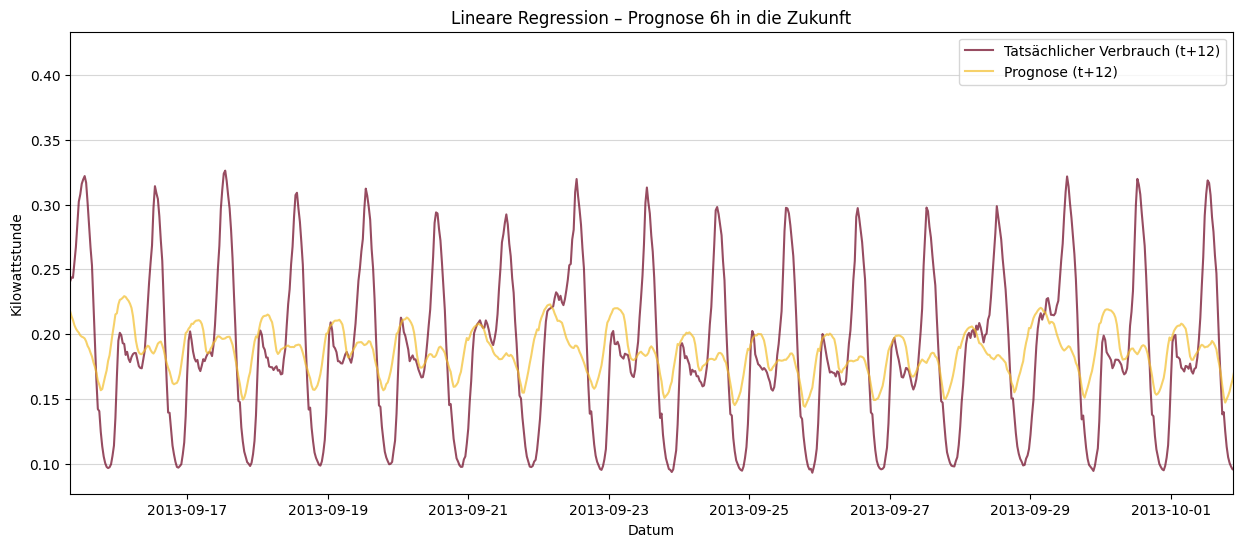

In [17]:
# Prognose plotten
fig, ax = plt.subplots(figsize=(15, 6))
ax.margins(x=0)

ax.plot(test.index, test["kwh_target"], color="#6B001E", alpha=0.7, label="Tatsächlicher Verbrauch (t+12)")
ax.plot(test.index, y_pred_a, color="#F3BE2B", alpha=0.7, label="Prognose (t+12)")

ax.set(
    title="Lineare Regression – Prognose 6h in die Zukunft",
    xlabel="Datum",
    ylabel="Kilowattstunde",
)
ax.legend()
ax.grid(axis="y", alpha=0.5)
ax.set_xlim(pd.Series(test.index).quantile(0.0), pd.Series(test.index).quantile(0.1))
plt.show()

### Metriken

In [18]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error

y_test_b = test["kwh_target"]

mse = mean_squared_error(y_test_b, y_pred_a)
rmse = root_mean_squared_error(y_test_b, y_pred_a)
r2 = r2_score(y_test_b, y_pred_a)
mae = mean_absolute_error(y_test_b, y_pred_a)

print(
    f"Regression Intercept: {model_a.intercept_}\n"
    f"Regression Coefficients: {model_a.coef_}\n"
    f"R²:\t{r2: .6f}\n"
    f"MSE:\t{mse: .6f}\n"
    f"RMSE:\t{rmse: .6f}\n"
    f"MAE:\t{mae: .6f}\n"
)

Regression Intercept: -0.0014103278421260246
Regression Coefficients: [-0.17802133 -0.1022918  -0.10753294 -0.0718153  -0.05593638 -0.00892106
 -0.01480164 -0.01592855  0.00797489  0.0212604   0.01684993 -0.22654543
  1.00640444 -0.27451251]
R²:	 0.155267
MSE:	 0.005083
RMSE:	 0.071295
MAE:	 0.057852



# Vorhersage mit Linearer Regression
Als Zielvariable wird das Residuum 6 Stunden in der Zukunft verwendet.

Für die eigentliche Vorhersage werden der zuvor berechnete Trend und Saisonalität wieder einberechnet. 

In [19]:
df_model = df.copy()
lags = []
for lag in range(1, 13):
    col_name = f"kwh_bereinigt_t-{lag}"
    df_model[col_name] = df_model["kwh_bereinigt"].shift(lag)
    lags.append(col_name)

df_model["kwh_trend_t12"] = df_model["kwh_trend"].shift(-12) # Shift von Trend um mit der Vorhersage übereinzustimmen
df_model["kwh_saison_t12"] = df_model["kwh_trendbereinigt_saison"].shift(-12) # Shift der Saisonalität um mit der Vorhersage übereinzustimmen
df_model["kwh_target"] = df_model["kwh_bereinigt"].shift(-12) # Zielwert: Vorherzusagener Wert 6 Stunden in der Zukunft 
df_model["kwh_target_final"] = df_model["kwh"].shift(-12) # Ursprünglichen Daten für den Metrik Vergleich
df_model = df_model.dropna()

# Train-Test-Split
split = int(len(df_model) * 0.8)
train = df_model.iloc[:split]
test = df_model.iloc[split:]

# Model Training
features_b = lags # Hier ohne Trend und Saisonalität da diese nicht gelernt werden soll
X_train_b = train[features_b]
y_train_b = train["kwh_target"] # Um 6 Stunden verschobenen Wert nehmen, nicht den Original Wert.
model_b = LinearRegression()
model_b.fit(X_train_b, y_train_b)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [20]:
# Prediction der Testdaten
X_test_b = test[features_b]
y_pred_residuum = model_b.predict(X_test_b) # Nur das Residuum wird hier vorhergesagt

# Trend und Saisonalität bei t+12 liegen durch .shift(-12) bereits im test-Index vor
y_pred_b = y_pred_residuum + test["kwh_trend_t12"] + test["kwh_saison_t12"]

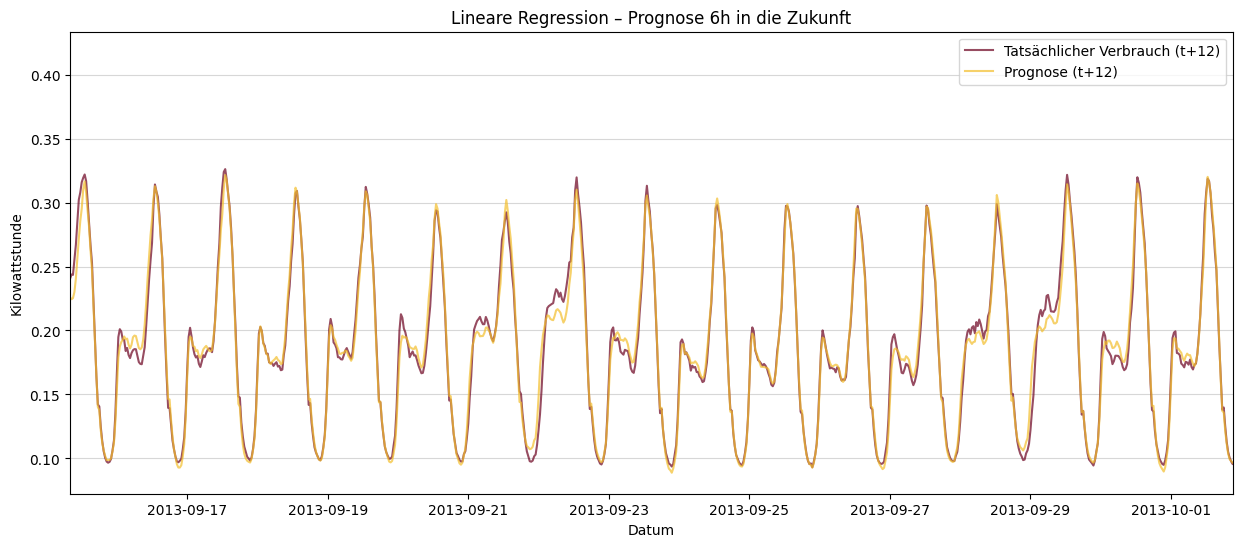

In [21]:
# Prognose plotten
fig, ax = plt.subplots(figsize=(15, 6))
ax.margins(x=0)

ax.plot(test.index, test["kwh_target_final"], color="#6B001E", alpha=0.7, label="Tatsächlicher Verbrauch (t+12)")
ax.plot(test.index, y_pred_b, color="#F3BE2B", alpha=0.7, label="Prognose (t+12)")

ax.set(
    title="Lineare Regression – Prognose 6h in die Zukunft",
    xlabel="Datum",
    ylabel="Kilowattstunde",
)
ax.legend()
ax.grid(axis="y", alpha=0.5)
ax.set_xlim(pd.Series(test.index).quantile(0.0), pd.Series(test.index).quantile(0.1))
plt.show()

In [22]:
y_test_b = test["kwh_target_final"]

mse = mean_squared_error(y_test_b, y_pred_b)
rmse = root_mean_squared_error(y_test_b, y_pred_b)
r2 = r2_score(y_test_b, y_pred_b)
mae = mean_absolute_error(y_test_b, y_pred_b)

print(
    f"Regression Intercept: {model_b.intercept_}\n"
    f"Regression Coefficients: {model_b.coef_}\n"
    f"R²:\t{r2: .6f}\n"
    f"MSE:\t{mse: .6f}\n"
    f"RMSE:\t{rmse: .6f}\n"
    f"MAE:\t{mae: .6f}\n"
)

Regression Intercept: -9.63704623189052e-06
Regression Coefficients: [-0.17302253 -0.0807065  -0.07050072 -0.04290325 -0.04879503 -0.01283276
 -0.01015768 -0.01499713  0.01124471  0.02070591  0.01351372 -0.11865602]
R²:	 0.986163
MSE:	 0.000083
RMSE:	 0.009125
MAE:	 0.006429



In [23]:
df_model.iloc[[-1]]

,KWH,kwh,meters,kwh_trend,kwh_trendbereinigt,kwh_trendbereinigt_saison,kwh_bereinigt,kwh_bereinigt_t-1,kwh_bereinigt_t-2,kwh_bereinigt_t-3,...,kwh_bereinigt_t-7,kwh_bereinigt_t-8,kwh_bereinigt_t-9,kwh_bereinigt_t-10,kwh_bereinigt_t-11,kwh_bereinigt_t-12,kwh_trend_t12,kwh_saison_t12,kwh_target,kwh_target_final
date,,,,,,,,,,,,,,,,,,,,,
2014-02-27 18:00:00,1524.923999,0.305719,4988,0.215511,0.090208,0.087759,0.002448,0.007475,0.009824,0.009428,...,0.007908,0.005714,0.007295,0.009248,0.007664,0.005693,0.215743,-0.00671,-0.000036,0.208997


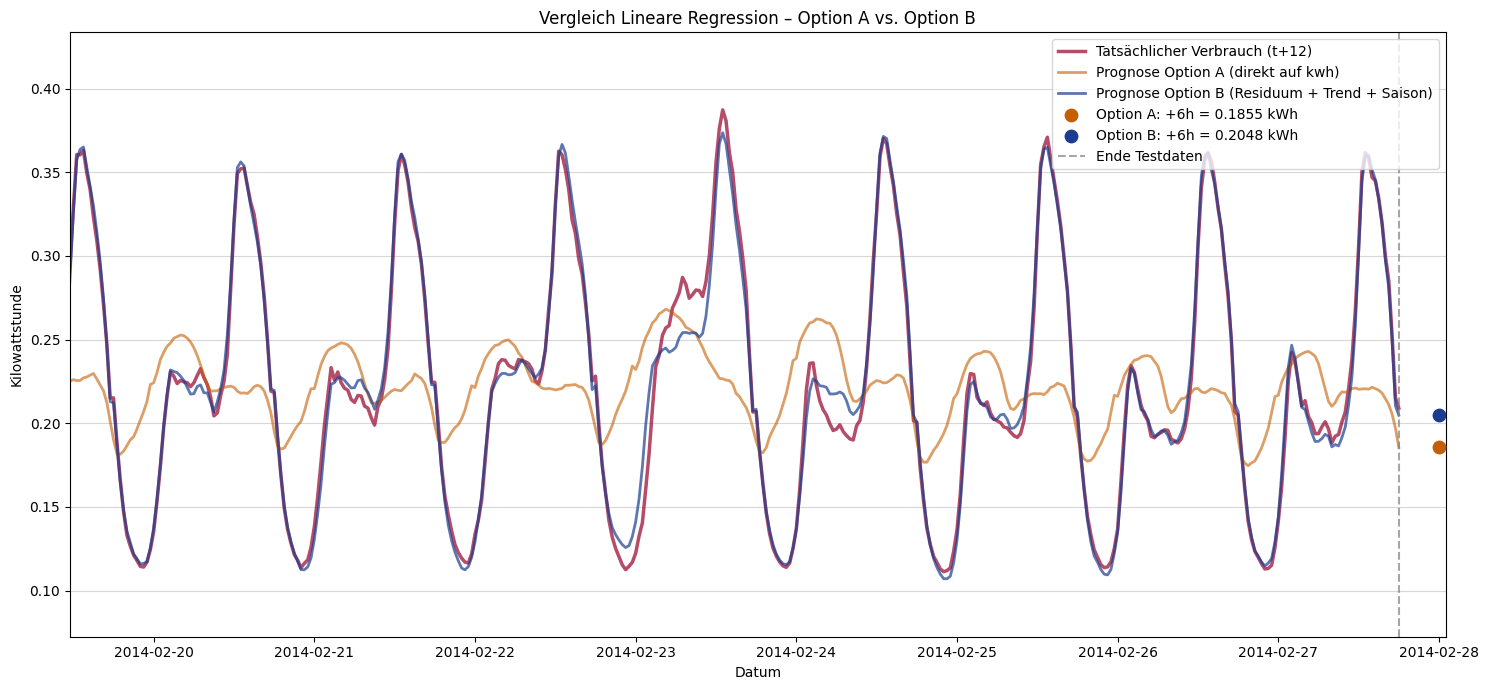

Metrik     Option A   Option B   Verbesserung
--------------------------------------------
R²           0.1553     0.9862        +535.1%
RMSE         0.0713     0.0091         +87.2%
MAE          0.0579     0.0064         +88.9%



In [24]:
# Letzter bekannter Datenpunkt für Zukunftsprognose
last_row = df_model.iloc[[-1]]
X_future_a = last_row[features_a]
X_future_b = last_row[features_b]

# Zukunftsprognose Option A
future_pred_a = model_a.predict(X_future_a)[0]
future_time = df_model.index[-1] + pd.Timedelta(hours=6)

# Zukunftsprognose Option B
future_residuum_b = model_b.predict(X_future_b)[0]
future_pred_b = future_residuum_b + last_row["kwh_trend_t12"].values[0] + last_row["kwh_saison_t12"].values[0]

fig, ax = plt.subplots(figsize=(15, 7))
ax.margins(x=0)

ax.plot(test.index, test["kwh_target_final"], color="#96002A", alpha=0.7, linewidth=2.5, label="Tatsächlicher Verbrauch (t+12)")
ax.plot(test.index, y_pred_a, color="#C45E00", alpha=0.6, linewidth=2, label="Prognose Option A (direkt auf kwh)")
ax.plot(test.index, y_pred_b, color="#1A3D8F", alpha=0.7, linewidth=2, label="Prognose Option B (Residuum + Trend + Saison)")

ax.scatter(future_time, future_pred_a, color="#C45E00", s=80, zorder=5, label=f"Option A: +6h = {future_pred_a:.4f} kWh")
ax.scatter(future_time, future_pred_b, color="#1A3D8F", s=80, zorder=5, label=f"Option B: +6h = {future_pred_b:.4f} kWh")
ax.axvline(x=df_model.index[-1], color="gray", linestyle="--", alpha=0.7, label="Ende Testdaten")

ax.set(
    title="Vergleich Lineare Regression – Option A vs. Option B",
    xlabel="Datum",
    ylabel="Kilowattstunde",
)
ax.set_xlim(pd.Series(test.index).quantile(0.95), future_time + pd.Timedelta(hours=1))
ax.legend()
ax.grid(axis="y", alpha=0.5)
plt.tight_layout()
plt.show()

r2_a, mse_a, rmse_a, mae_a = 0.155267, 0.005083, 0.071295, 0.057852  # Werte von Option A einsetzen
r2_b, mse_b, rmse_b, mae_b = 0.986163, 0.000083, 0.009125, 0.006429  # Werte von Option B einsetzen

# Metriken
r2_diff   = (r2_b   - r2_a)   / abs(r2_a)   * 100
rmse_diff = (rmse_a - rmse_b) / rmse_a       * 100
mae_diff  = (mae_a  - mae_b)  / mae_a        * 100

print(
    f"{'Metrik':<8} {'Option A':>10} {'Option B':>10} {'Verbesserung':>14}\n"
    f"{'-'*44}\n"
    f"{'R²':<8} {r2_a:>10.4f} {r2_b:>10.4f} {r2_diff:>+13.1f}%\n"
    f"{'RMSE':<8} {rmse_a:>10.4f} {rmse_b:>10.4f} {rmse_diff:>+13.1f}%\n"
    f"{'MAE':<8} {mae_a:>10.4f} {mae_b:>10.4f} {mae_diff:>+13.1f}%\n"
)

In [25]:
# Training
arima_model = ARIMA(train["kwh_bereinigt"], order=(1, 0, 0)) # AR(1) Prozess
arima_fitted = arima_model.fit()

# Prognose auf Testset: jeweils 12 Schritte voraus
arima_pred_residuum = arima_fitted.forecast(steps=len(test) + 12)

# Nur die zum Testset passenden t+12 Werte
arima_pred_residuum = arima_pred_residuum.iloc[12:12+len(test)].values

# Trend + Saisonalität dazuaddieren
arima_pred_final = arima_pred_residuum + test["kwh_trend_t12"].values + test["kwh_saison_t12"].values

# Metriken
r2_arima   = r2_score(test["kwh_target_final"], arima_pred_final)
mse_arima  = mean_squared_error(test["kwh_target_final"], arima_pred_final)
rmse_arima = np.sqrt(mse_arima)
mae_arima  = mean_absolute_error(test["kwh_target_final"], arima_pred_final)

print(
    f"R²:\t{r2_arima: .6f}\n"
    f"MSE:\t{mse_arima: .6f}\n"
    f"RMSE:\t{rmse_arima: .6f}\n"
    f"MAE:\t{mae_arima: .6f}\n"
)

R²:	 0.982970
MSE:	 0.000102
RMSE:	 0.010123
MAE:	 0.006908



## SARIMA

SARIMA wurde mit einer saisonalen Periode von 48 (entspricht einem Tageszyklus 
bei 30-Minuten-Takt) getestet. Das Modell konvergiert dabei zum Mittelwert und 
erfasst die Saisonalität nicht sinnvoll. 

Mit saisonaler Differenzierung (d=1) ist die Trainingszeit nicht praktikabel.

In [26]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima_model = SARIMAX(
    train["kwh_trendbereinigt"], # Training auf trendbereinigten Daten (Saisonalität noch enthalten)
    order=(1, 0, 0),           # AR(1) wie zuvor
    seasonal_order=(1, 0, 0, 48)  # Saisonaler AR(1) mit Periode 48 (ein Tag)
)
sarima_fitted = sarima_model.fit(disp=False)

# Prognose
sarima_pred_saisonbereinigt = sarima_fitted.forecast(steps=len(test) + 12)
sarima_pred_saisonbereinigt = sarima_pred_saisonbereinigt.iloc[12:12+len(test)].values

# Nur Trend dazuaddieren
sarima_pred_final = sarima_pred_saisonbereinigt + test["kwh_trend_t12"].values

# Metriken
r2_sarima   = r2_score(test["kwh_target_final"], sarima_pred_final)
mse_sarima  = mean_squared_error(test["kwh_target_final"], sarima_pred_final)
rmse_sarima = np.sqrt(mse_sarima)
mae_sarima  = mean_absolute_error(test["kwh_target_final"], sarima_pred_final)

print(
    f"R²:\t{r2_sarima: .6f}\n"
    f"MSE:\t{mse_sarima: .6f}\n"
    f"RMSE:\t{rmse_sarima: .6f}\n"
    f"MAE:\t{mae_sarima: .6f}\n"
)

R²:	 0.223505
MSE:	 0.004672
RMSE:	 0.068355
MAE:	 0.052873



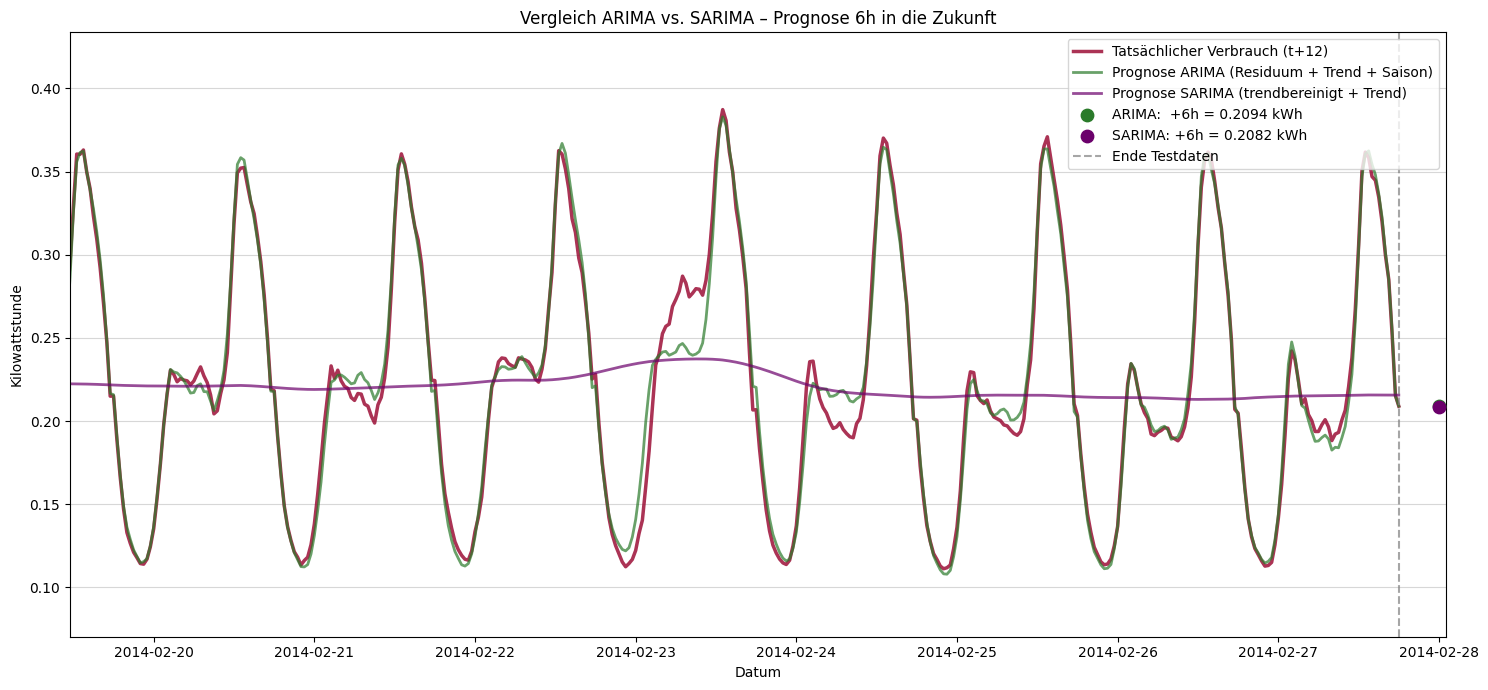

Metrik        ARIMA     SARIMA   Verbesserung
--------------------------------------------
R²           0.9830     0.2235         -77.3%
RMSE         0.0101     0.0684        -575.3%
MAE          0.0069     0.0529        -665.3%



In [27]:
# Zukunftsprognose ARIMA (+6h)
arima_future = arima_fitted.apply(test["kwh_bereinigt"]).forecast(steps=12)
future_pred_arima = arima_future.iloc[-1] + last_row["kwh_trend_t12"].values[0] + last_row["kwh_saison_t12"].values[0]

# Zukunftsprognose SARIMA (+6h)
sarima_future = sarima_fitted.apply(test["kwh_trendbereinigt"]).forecast(steps=12)
future_pred_sarima = sarima_future.iloc[-1] + last_row["kwh_trend_t12"].values[0]

future_time = df_model.index[-1] + pd.Timedelta(hours=6)

fig, ax = plt.subplots(figsize=(15, 7))
ax.margins(x=0)

ax.plot(test.index, test["kwh_target_final"], color="#96002A", alpha=0.8, linewidth=2.5, label="Tatsächlicher Verbrauch (t+12)")
ax.plot(test.index, arima_pred_final,         color="#2A7A2A", alpha=0.7, linewidth=2,   label="Prognose ARIMA (Residuum + Trend + Saison)")
ax.plot(test.index, sarima_pred_final,        color="#6B006B", alpha=0.7, linewidth=2,   label="Prognose SARIMA (trendbereinigt + Trend)")

ax.scatter(future_time, future_pred_arima,  color="#2A7A2A", s=80, zorder=5, label=f"ARIMA:  +6h = {future_pred_arima:.4f} kWh")
ax.scatter(future_time, future_pred_sarima, color="#6B006B", s=80, zorder=5, label=f"SARIMA: +6h = {future_pred_sarima:.4f} kWh")
ax.axvline(x=df_model.index[-1], color="gray", linestyle="--", alpha=0.7, label="Ende Testdaten")

ax.set(
    title="Vergleich ARIMA vs. SARIMA – Prognose 6h in die Zukunft",
    xlabel="Datum",
    ylabel="Kilowattstunde",
)
ax.set_xlim(pd.Series(test.index).quantile(0.95), future_time + pd.Timedelta(hours=1))
ax.legend()
ax.grid(axis="y", alpha=0.5)
plt.tight_layout()
plt.show()

# Metriken
r2_diff_as   = (r2_sarima   - r2_arima)   / abs(r2_arima)   * 100
rmse_diff_as = (rmse_arima  - rmse_sarima) / rmse_arima      * 100
mae_diff_as  = (mae_arima   - mae_sarima)  / mae_arima       * 100

print(
    f"{'Metrik':<8} {'ARIMA':>10} {'SARIMA':>10} {'Verbesserung':>14}\n"
    f"{'-'*44}\n"
    f"{'R²':<8} {r2_arima:>10.4f} {r2_sarima:>10.4f} {r2_diff_as:>+13.1f}%\n"
    f"{'RMSE':<8} {rmse_arima:>10.4f} {rmse_sarima:>10.4f} {rmse_diff_as:>+13.1f}%\n"
    f"{'MAE':<8} {mae_arima:>10.4f} {mae_sarima:>10.4f} {mae_diff_as:>+13.1f}%\n"
)

### Varianzen

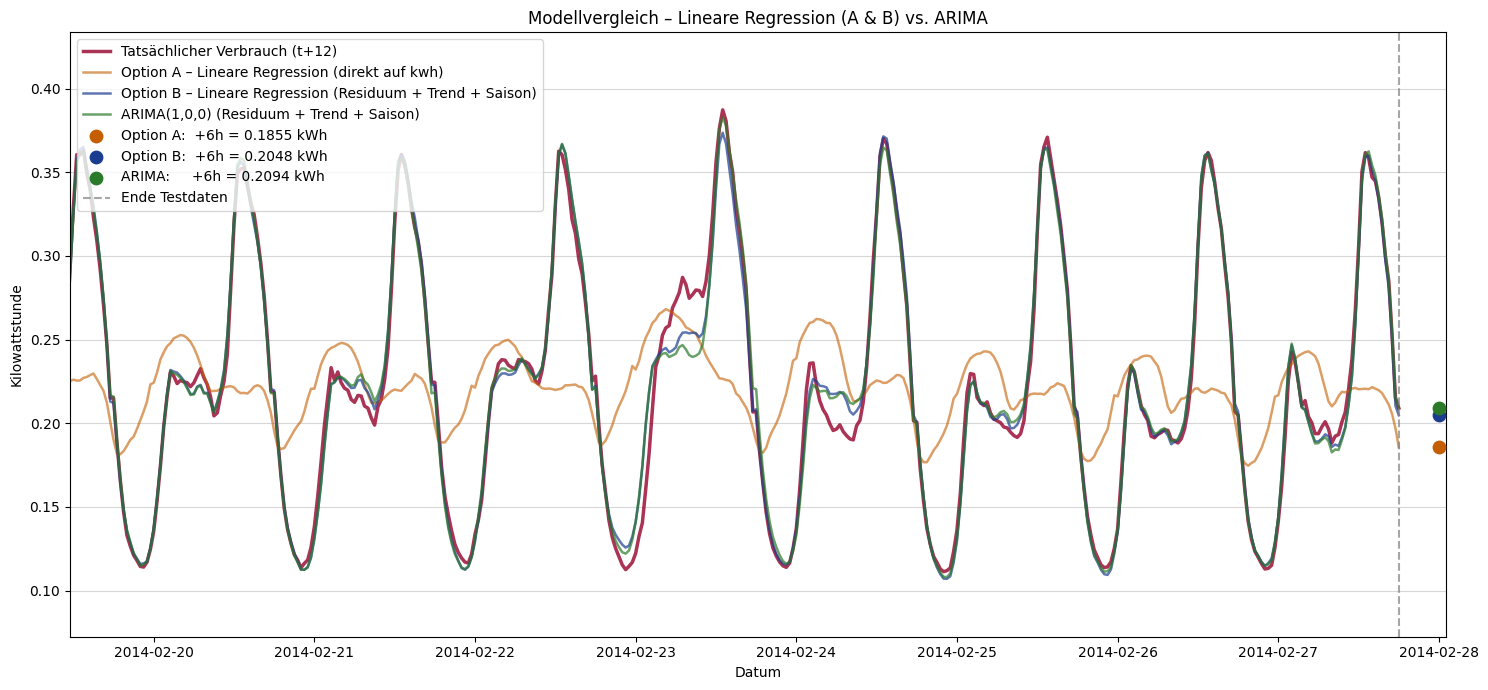

Metrik     Option A   Option B      ARIMA
--------------------------------------------------
R²           0.1553     0.9862 ◄     0.9830
RMSE         0.0713     0.0091 ◄     0.0101
MAE          0.0579     0.0064 ◄     0.0069



In [39]:
# Zukunftsprognose ARIMA (+6h)
arima_future = arima_fitted.apply(test["kwh_bereinigt"]).forecast(steps=12)
future_pred_arima = arima_future.iloc[-1] + last_row["kwh_trend_t12"].values[0] + last_row["kwh_saison_t12"].values[0]
future_time = df_model.index[-1] + pd.Timedelta(hours=6)

fig, ax = plt.subplots(figsize=(15, 7))
ax.margins(x=0)

ax.plot(test.index, test["kwh_target_final"], color="#96002A", alpha=0.8, linewidth=2.5, label="Tatsächlicher Verbrauch (t+12)")
ax.plot(test.index, y_pred_a,                color="#C45E00", alpha=0.6, linewidth=1.8, label="Option A – Lineare Regression (direkt auf kwh)")
ax.plot(test.index, y_pred_b,            color="#1A3D8F", alpha=0.7, linewidth=1.8, label="Option B – Lineare Regression (Residuum + Trend + Saison)")
ax.plot(test.index, arima_pred_final,        color="#2A7A2A", alpha=0.7, linewidth=1.8, label="ARIMA(1,0,0) (Residuum + Trend + Saison)")

ax.scatter(future_time, future_pred_a,     color="#C45E00", s=80, zorder=5, label=f"Option A:  +6h = {future_pred_a:.4f} kWh")
ax.scatter(future_time, future_pred_b,     color="#1A3D8F", s=80, zorder=5, label=f"Option B:  +6h = {future_pred_b:.4f} kWh")
ax.scatter(future_time, future_pred_arima, color="#2A7A2A", s=80, zorder=5, label=f"ARIMA:     +6h = {future_pred_arima:.4f} kWh")
ax.axvline(x=df_model.index[-1], color="gray", linestyle="--", alpha=0.7, label="Ende Testdaten")

ax.set(
    title="Modellvergleich – Lineare Regression (A & B) vs. ARIMA",
    xlabel="Datum",
    ylabel="Kilowattstunde",
)
ax.set_xlim(pd.Series(test.index).quantile(0.95), future_time + pd.Timedelta(hours=1))
ax.legend()
ax.grid(axis="y", alpha=0.5)
plt.tight_layout()
plt.show()

# Metriken
best_r2   = max(r2_a,   r2_b,   r2_arima)
best_rmse = min(rmse_a, rmse_b, rmse_arima)
best_mae  = min(mae_a,  mae_b,  mae_arima)

def mark(val, best): return " ◄" if val == best else ""

print(
    f"{'Metrik':<8} {'Option A':>10} {'Option B':>10} {'ARIMA':>10}\n"
    f"{'-'*50}\n"
    f"{'R²':<8} {r2_a:>10.4f}{mark(r2_a, best_r2)} {r2_b:>10.4f}{mark(r2_b, best_r2)} {r2_arima:>10.4f}{mark(r2_arima, best_r2)}\n"
    f"{'RMSE':<8} {rmse_a:>10.4f}{mark(rmse_a, best_rmse)} {rmse_b:>10.4f}{mark(rmse_b, best_rmse)} {rmse_arima:>10.4f}{mark(rmse_arima, best_rmse)}\n"
    f"{'MAE':<8} {mae_a:>10.4f}{mark(mae_a, best_mae)} {mae_b:>10.4f}{mark(mae_b, best_mae)} {mae_arima:>10.4f}{mark(mae_arima, best_mae)}\n"
)

In [40]:
def variances(df: pd.DataFrame, decomposition: pd.DataFrame = None):
    df_var = df.copy()
    if decomposition:
        df_var["trend"] = decomposition.trend
        df_var["seasonal"] = decomposition.seasonal
        df_var["resid"] = decomposition.resid
    else:
        df_var["trend"] = df_var["kwh_trend"]
        df_var["seasonal"] = df_var["kwh_trendbereinigt_sasion"]
        df_var["resid"] = df_var["kwh_bereinigt"]

    variances = df_var[["kwh", "trend", "seasonal", "resid"]].var()
    variances["ryth"] = decomposition.seasonal.var()
    portions = variances / variances["kwh"]

    print(
        f"Von der Varianz der Zeitreihe werden:\n\t{(portions['trend'] * 100):2.1f}% durch den Trend erklärt"
        f"\n\t{(portions['ryth'] * 100):2.1f}% durch die Periodizität erklärt"
        f"\n\t{(portions['resid'] * 100):2.1f}% haben andere Ursachen (Residuum)"
    )


variances(df, decomposition)

Von der Varianz der Zeitreihe werden:
	25.2% durch den Trend erklärt
	71.7% durch die Periodizität erklärt
	1.7% haben andere Ursachen (Residuum)


Standard Tarif:


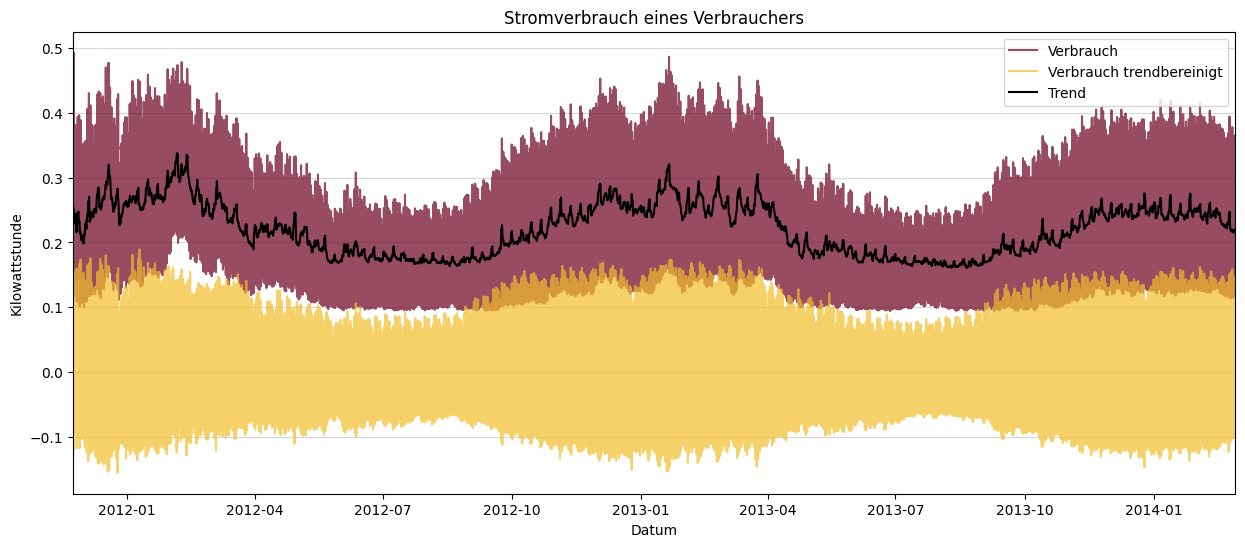

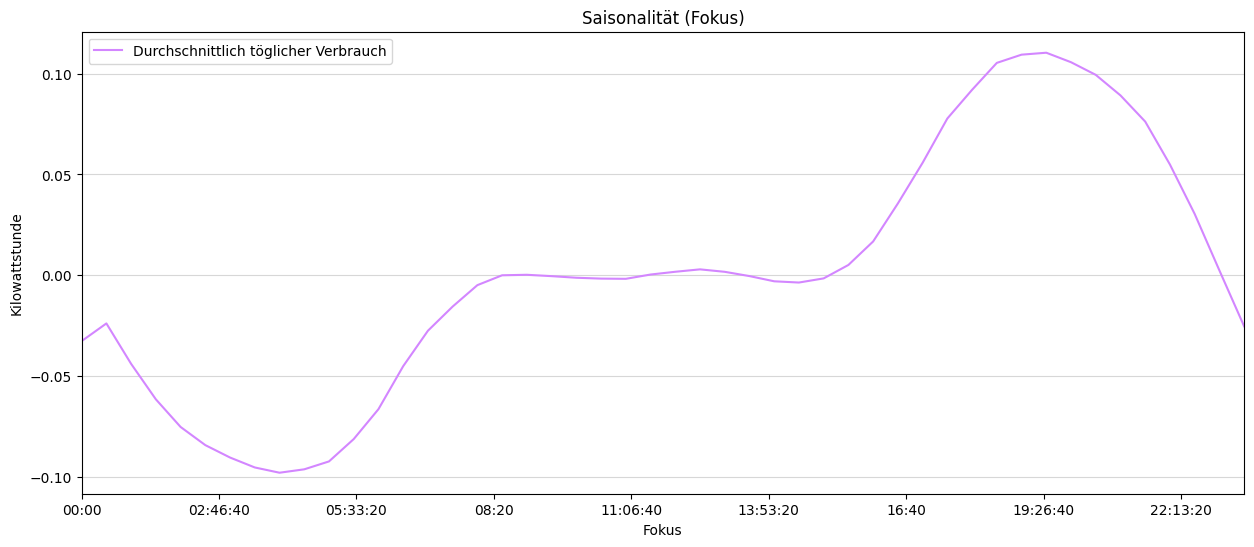

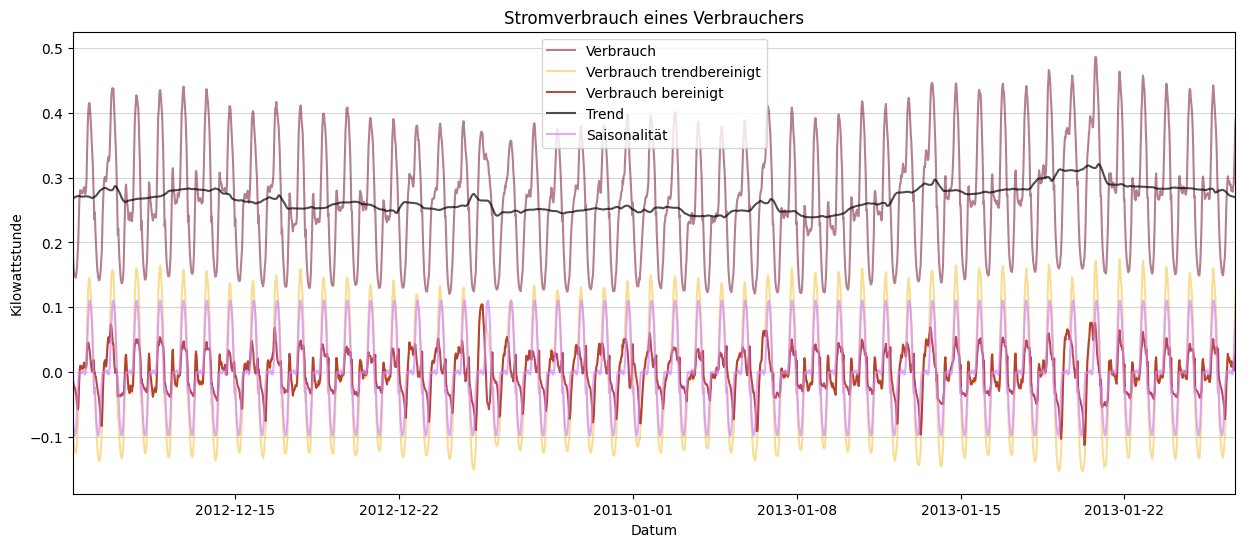

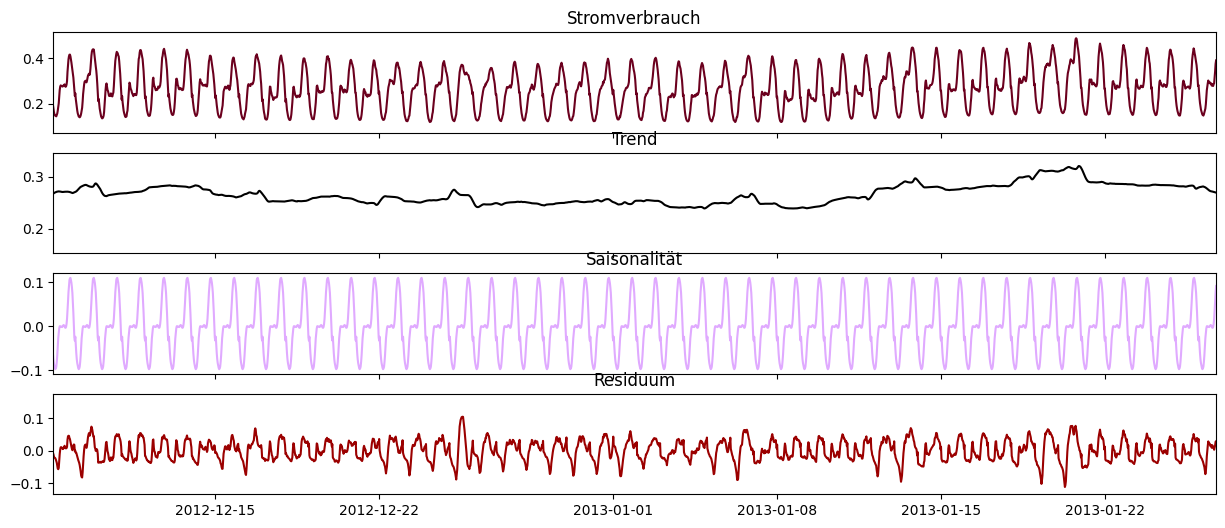

Von der Varianz der Zeitreihe werden:
	25.9% durch den Trend erklärt
	70.9% durch die Periodizität erklärt
	1.8% haben andere Ursachen (Residuum)


Variabler Tarif:


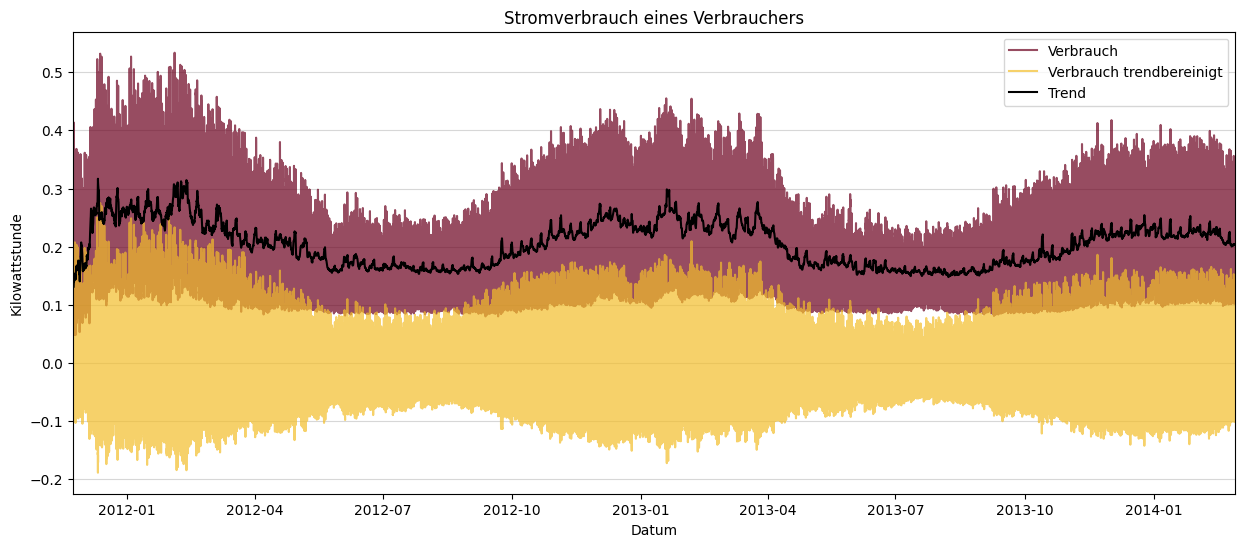

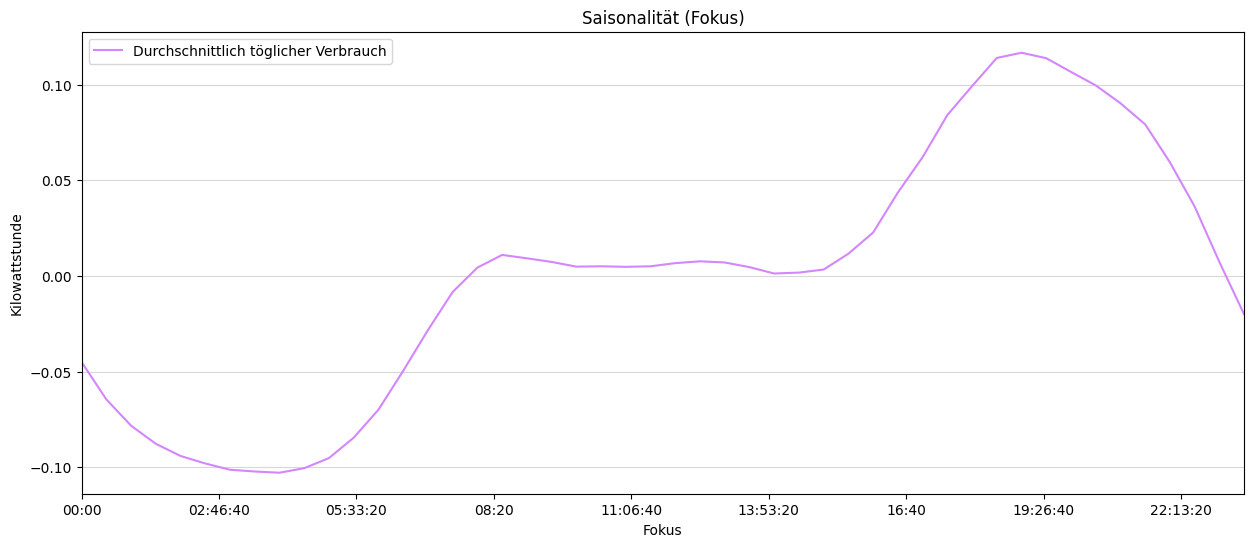

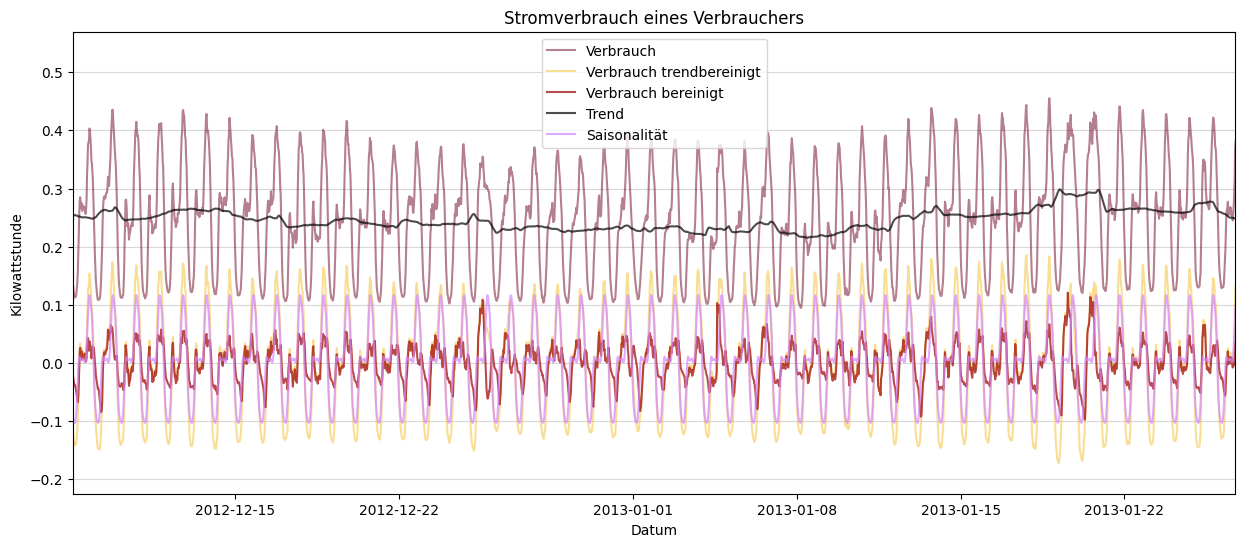

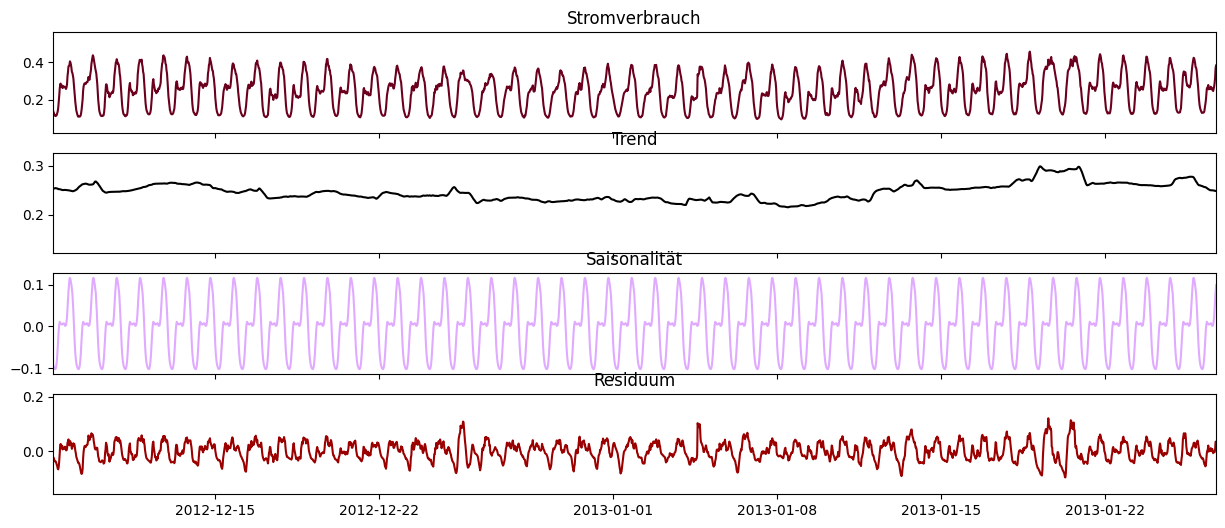

Von der Varianz der Zeitreihe werden:
	21.2% durch den Trend erklärt
	74.9% durch die Periodizität erklärt
	2.5% haben andere Ursachen (Residuum)


In [41]:
df = pd.read_csv("data.csv")


def prep_data(df: pd.DataFrame, rate: str) -> pd.DataFrame:
    df["date"] = pd.to_datetime(df["DateTime"])
    df = df.loc[df["rate"] == rate]
    df["kwh"] = df["KWH"] / df["meters"]
    return df[["date", "KWH", "kwh", "meters"]].set_index("date")[["kwh"]].sort_index().asfreq("30min")


def analyse(df: pd.DataFrame) -> pd.DataFrame:
    return analyse_cleaned(analyse_seasonality(analyse_trend(df)))


df_std = prep_data(df, "Std")
df_tou = prep_data(df, "ToU")

print("Standard Tarif:")
df_std = analyse(df_std)
variances(df_std, STL(df_std["kwh"], period=48).fit())
print("\n\nVariabler Tarif:")
df_tou = analyse(df_tou)
variances(df_tou, STL(df_tou["kwh"], period=48).fit())